In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
# Load raw data
df_train = pd.read_csv('data/train.csv', dtype=np.float32)
df_test = pd.read_csv('data/test.csv', dtype=np.float32)

print(f"Train shape: {df_train.shape}")
print(f"Test shape: {df_test.shape}")

Dimensions Train: (76905, 7595)
Dimensions Test: (8346, 7592)


In [3]:
df_train.head()

,id,demand_0_0,demand_0_1,demand_0_2,demand_0_3,demand_0_4,demand_0_5,demand_0_6,demand_0_7,demand_0_8,...,param_year2_f10,param_year2_f11,param_year2_f12,param_year2_f13,param_year2_f14,param_year2_f15,param_year2_f16,wip,investissement,satisfaction
0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,4.0,2.0,1.0,1.0,18.0,8.0,18.0,21933054.0,1000000.0,0.380446
1,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,2.0,2.0,2.0,2.0,16.0,9.0,20.0,25137482.0,875000.0,0.535928
2,2.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,2.0,2.0,2.0,2.0,18.0,12.0,18.0,27033844.0,875000.0,0.771907
3,3.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,2.0,2.0,2.0,2.0,25.0,14.0,18.0,28365370.0,875000.0,0.775773
4,4.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,3.0,3.0,1.0,3.0,22.0,9.0,18.0,26715704.0,1250000.0,0.757688



--- Statistiques des Cibles ---
              wip  investissement  satisfaction
count     76905.0    7.690500e+04  76905.000000
mean   29121896.0    1.000426e+06      0.743514
std     4667476.0    1.411611e+05      0.206943
min    10561853.0    7.500000e+05      0.176923
25%    25914252.0    8.750000e+05      0.643623
50%    28820450.0    1.000000e+06      0.808861
75%    32535234.0    1.125000e+06      0.908136
max    45222732.0    1.250000e+06      0.982713


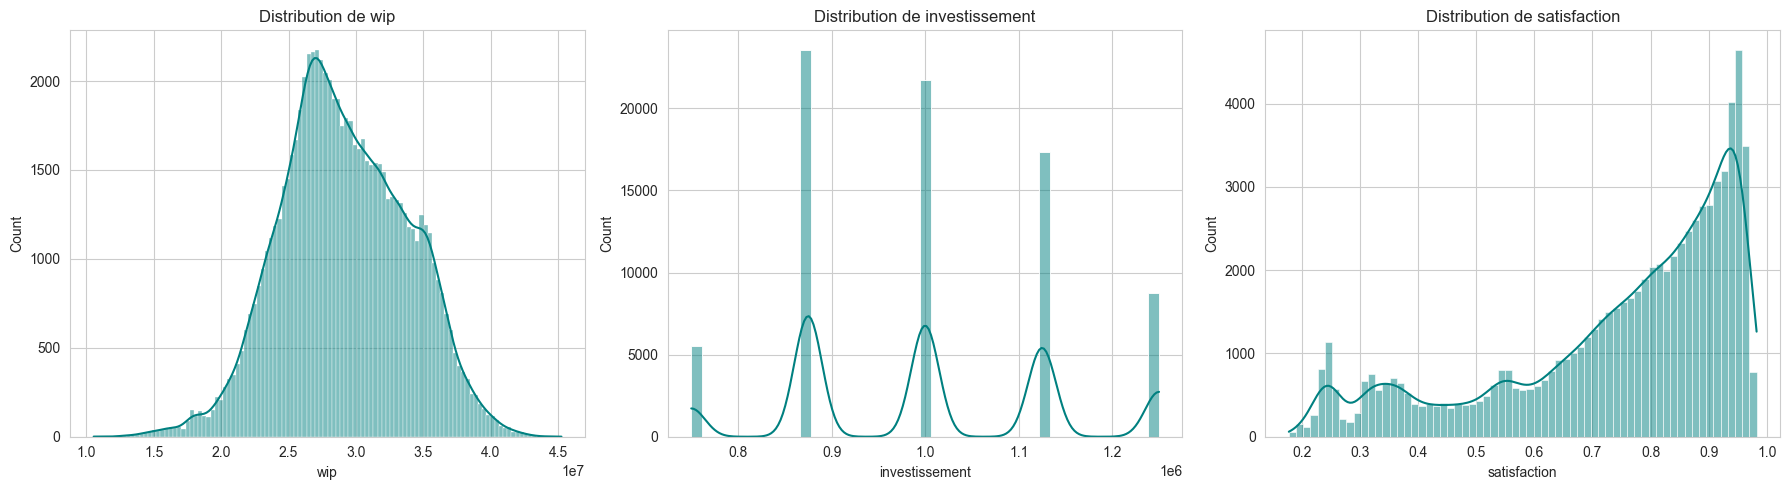


--- Corrélation entre les KPIs (Targets) ---
                     wip  investissement  satisfaction
wip             1.000000       -0.007051      0.395153
investissement -0.007051        1.000000      0.031110
satisfaction    0.395153        0.031110      1.000000


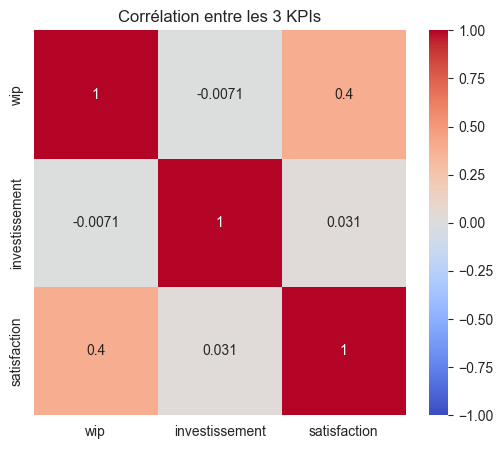

In [ ]:
# Target analysis

targets = ['wip', 'investissement', 'satisfaction']

print("\n--- Target Statistics ---")
print(df_train[targets].describe())

# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(targets):
    sns.histplot(df_train[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# Correlation between KPIs
print("\n--- KPI Correlation Matrix ---")
target_corr = df_train[targets].corr()
print(target_corr)

plt.figure(figsize=(6, 5))
sns.heatmap(target_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation between the 3 KPIs")
plt.show()